# End-to-End ML Project

In the previous notebooks you trained your first models on datasets that were ready to use. A real project needs more than training a model. You need to know which problem you are solving, understand and prepare the data, train and evaluate models, and put the final model to use.

This notebook walks through one small project from start to finish. It follows **CRISP-DM**, the Cross-Industry Standard Process for Data Mining. CRISP-DM was written in the late 1990s by a group of companies, and it is still a common way to structure data science and machine learning projects. It has six stages:

<img src="../images/crispdm.png" alt="The CRISP-DM cycle: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation and Deployment, with arrows in both directions between neighboring stages" width="55%">

The arrows go in both directions. You rarely go through the stages once: what you find in one stage often sends you back to an earlier one. Each section of this notebook is one stage, and the diagram at the top of each section marks where you are.

The project is small on purpose, so that you can see the whole process at once. The next two themes go deeper into the stages: [Data Preparation](005_data_prep.ipynb) and [Data Understanding](006_data_understanding.ipynb) in Theme 2, and [Modeling & Evaluation](007_modeling_and_evaluation.ipynb) at the start of Theme 3.

### Outline

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment
7. What comes next

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Business Understanding

<img src="../images/015_end_to_end_ml/crispdm_1.png" alt="The CRISP-DM cycle with stage 1, Business Understanding, marked by a red box" width="55%">

A project starts with the problem that the model should help to solve. The data in this notebook is real: the Palmer penguins dataset from [Getting Started](001_getting_started.ipynb), with measurements of 344 penguins of three species (Adelie, Chinstrap and Gentoo) on three islands in Antarctica, collected by Dr. Kristen Gorman and the [Palmer Station Long Term Ecological Research program](https://pallter.marine.rutgers.edu/). The project around it is made up for this notebook.

<img src="../images/penguins/penguin_species.jpg" alt="Photos of the three penguin species: an Adelie penguin on snow, a Chinstrap penguin with the thin black line under its chin, and a Gentoo penguin with an orange bill and a white patch above its eye" width="70%">

<small>Adelie: NOAA NMFS SWFSC Antarctic Marine Living Resources (AMLR) Program, Wikimedia Commons, public domain. Chinstrap: Dr. Wayne Trivelpiece, NOAA, Wikimedia Commons, public domain. Gentoo: Jay Ruzesky, Unsplash via Wikimedia Commons, CC0.</small>

A team of ecologists counts the penguins of each species in colonies along the coast. Telling the three species apart takes an expert, and there are not enough experts to visit every colony. Volunteers can visit more colonies, and they can measure a penguin: the length of its flipper (wing), the length and depth of its culmen (the upper ridge of the bill), and its body mass.

<img src="../images/penguins/penguin_measurements.jpg" alt="Photo of a Gentoo penguin with the three measurements marked: flipper length along the flipper, and, in a close-up of the head, culmen length along the top of the bill from its base to the tip and culmen depth from the top to the bottom of the bill at its base" width="70%">

<small>Photo: Kyle Bowman, Wikimedia Commons, CC0. Measurements added for this course.</small>

The team asks: can a model tell the species from these four measurements, so that volunteers can do the counting?

Before you look at the data, write down the answers to a few questions together with the client:

* **What should the model predict?** The species of a penguin: one of three classes, so this is a classification problem.
* **How will the model be used?** Volunteers measure penguins in new colonies, on other islands than the ones in the data. So the model may only use what a volunteer can measure: the four measurements. It may not use the island, and it may not use the sex of the penguin, because volunteers cannot tell male and female penguins apart by looking at them.
* **When is the model good enough?** The team counts each species, so every species matters, also the less common ones. The team agrees on a success criterion: the model identifies at least 95% of all penguins correctly, and at least 90% of the penguins of each species.
* **Which data is there?** A table of 344 penguins whose species an expert identified, with the four measurements, the island and the sex.

These answers guide the rest of the project. They decide which features you may use (section 3) and how you judge the model (section 5).

## 2. Data Understanding

<img src="../images/015_end_to_end_ml/crispdm_2.png" alt="The CRISP-DM cycle with stage 2, Data Understanding, marked by a red box" width="55%">

In this stage you get to know the data: what each column contains, which values are missing or wrong, and how the features relate to the target. We load the dataset from [OpenML](https://www.openml.org/), as in the [Classification](002_classification.ipynb) notebook. `frame` holds the whole table as a DataFrame.

In [2]:
from sklearn.datasets import fetch_openml

df = fetch_openml(name="penguins", version=1, as_frame=True).frame
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
df.shape

(344, 7)

Each row is one penguin. `species` is the target, the column the model should predict.

Before we look closer, we set aside a test set. We use it only once, in section 5, to check the final model. If you study the test penguins now, what you see can influence your decisions about features and models, and then the final check is no longer a fair test on unseen data. So we explore the training set only.

`stratify=df['species']` keeps the share of each species the same in both sets.

In [4]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=0, stratify=df['species'])
train_df.shape, test_df.shape

((275, 7), (69, 7))

First, the missing values in each column:

In [5]:
train_df.isna().sum()

species              0
island               0
culmen_length_mm     1
culmen_depth_mm      1
flipper_length_mm    1
body_mass_g          1
sex                  7
dtype: int64

One penguin has no measurements at all, and seven have no value for `sex`. Let's look at the values of `sex`:

In [6]:
train_df['sex'].value_counts(dropna=False)

sex
FEMALE    139
MALE      128
NaN         7
_           1
Name: count, dtype: int64

Next to `MALE`, `FEMALE` and the missing values (`NaN`), one penguin has the value `_`. That is probably a typing error. In a real project you would ask the team what it means. Here it does not matter, because the model will not use `sex`.

How many penguins of each species are there?

In [7]:
train_df['species'].value_counts()

species
Adelie       122
Gentoo        99
Chinstrap     54
Name: count, dtype: int64

Chinstrap penguins are less common than the other two species. That is one reason to check the result for each species in section 5, and not only the overall accuracy.

The mean of each measurement per species:

In [8]:
features = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

train_df.groupby('species', observed=True)[features].mean().round(1)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.7,18.2,189.9,3676.4
Chinstrap,48.8,18.4,195.5,3739.4
Gentoo,47.5,14.9,217.0,5050.0


Gentoo penguins are the heaviest, with the longest flippers and the shallowest culmen. Adelie penguins have a much shorter culmen than the other two species. Chinstrap penguins have a long culmen, like Gentoo, but a deep one, like Adelie.

A plot shows whether the species also differ for individual penguins, and not only on average:

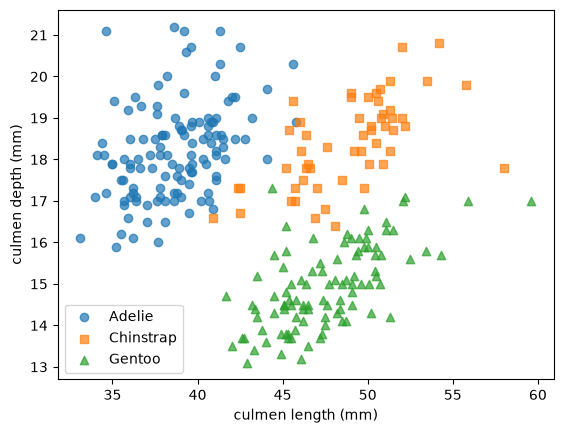

In [9]:
plt.figure(dpi=100)
for species, marker in zip(['Adelie', 'Chinstrap', 'Gentoo'], ['o', 's', '^']):
    group = train_df[train_df['species'] == species]
    plt.scatter(group['culmen_length_mm'], group['culmen_depth_mm'], marker=marker, alpha=0.7, label=species)
plt.xlabel('culmen length (mm)')
plt.ylabel('culmen depth (mm)')
plt.legend()

With only two of the four measurements, the three species already form three groups that hardly overlap. That is a good sign: the measurements carry the information the model needs.

Finally, the islands:

In [10]:
pd.crosstab(train_df['species'], train_df['island'])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,37,44,41
Chinstrap,0,54,0
Gentoo,99,0,0


In this data, Gentoo penguins live only on Biscoe and Chinstrap penguins only on Dream. A model that is allowed to use `island` would learn these shortcuts and look very good on this data. In a new colony on another island they are useless. This confirms the decision from section 1 to leave the island out.

## 3. Data Preparation

<img src="../images/015_end_to_end_ml/crispdm_3.png" alt="The CRISP-DM cycle with stage 3, Data Preparation, marked by a red box" width="55%">

In this stage you turn the raw table into the inputs `X` and the target `y` that a model can learn from. Here that takes two decisions:

* **Features:** the four measurements, as decided in section 1.
* **Missing values:** two penguins in the whole dataset have no measurements, one in the training set and one in the test set. A model cannot predict anything for a penguin without measurements, so we remove these two rows from both sets. When only some values of a row are missing, you can often fill them in instead; the [Data Preparation](005_data_prep.ipynb) notebook shows how.

We apply the same steps to the training set and to the test set.

In [11]:
train_clean = train_df.dropna(subset=features)
test_clean = test_df.dropna(subset=features)

X_train, y_train = train_clean[features], train_clean['species']
X_test, y_test = test_clean[features], test_clean['species']

X_train.shape, X_test.shape

((274, 4), (68, 4))

Many projects need more preparation than this. Models such as support vector machines need features on similar scales, and text columns such as `island` must be turned into numbers before a model can use them. We use a random forest, which does not need scaled features, and no text columns, so neither step is needed here. The [Data Preparation](005_data_prep.ipynb) notebook covers both.

## 4. Modeling

<img src="../images/015_end_to_end_ml/crispdm_4.png" alt="The CRISP-DM cycle with stage 4, Modeling, marked by a red box" width="55%">

In this stage you train models. Start with a baseline, as in the [Regression](003_regression.ipynb) notebook: a "model" that ignores the features. For classification, the simplest baseline always predicts the most common class of the training set. scikit-learn has it as `DummyClassifier`. Any real model must do better than this.

In [12]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](3,)","[0.44,0.2 ,0.36]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[object](3,)","['Adelie','Chinstrap','Gentoo']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](4,)","['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,4
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


Now a random forest, the model from the [Classification](002_classification.ipynb) notebook, with its default hyperparameters:

In [13]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=0)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In a larger project you would try several models and hyperparameters in this stage, and compare them without using the test set. The [Modeling & Evaluation](007_modeling_and_evaluation.ipynb) notebook shows how. Here we keep the first model and move on.

## 5. Evaluation

<img src="../images/015_end_to_end_ml/crispdm_5.png" alt="The CRISP-DM cycle with stage 5, Evaluation, marked by a red box" width="55%">

In this stage you check whether the model meets the success criterion from section 1. Now, and only now, we use the test set.

In [14]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

print(f"baseline accuracy:      {accuracy_score(y_test, baseline.predict(X_test)):.3f}")
print(f"random forest accuracy: {accuracy_score(y_test, y_pred):.3f}")

baseline accuracy:      0.441
random forest accuracy: 0.985


The baseline predicts Adelie for every penguin and gets 44% right, the share of Adelie penguins in the test set. The random forest is far better. The success criterion also asks for every species, so we check the share of correct predictions per species, and the confusion matrix, which shows the true species in the rows and the predicted species in the columns.

species
Adelie       0.967
Chinstrap    1.000
Gentoo       1.000
Name: correct, dtype: float64


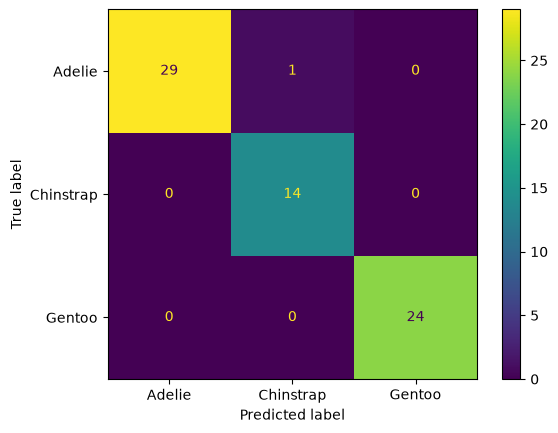

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

results = pd.DataFrame({'species': y_test, 'correct': y_test == y_pred})
print(results.groupby('species', observed=True)['correct'].mean().round(3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

The model identifies about 98.5% of the test penguins correctly, and at least 96.7% of each species. Both parts of the success criterion are met.

Two cautions. First, the test set has only 68 penguins, so one mistake changes the accuracy by 1.5 percentage points. With another split, the numbers would be a bit different. The [Modeling & Evaluation](007_modeling_and_evaluation.ipynb) notebook shows cross-validation, which gives a more reliable estimate. Second, a good score is not the end of evaluation. Look at the mistakes too:

In [16]:
test_clean[y_test != y_pred]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,MALE


The only mistake is an Adelie penguin with a culmen of 46 mm, which the model takes for a Chinstrap. Adelie penguins have a culmen of 38.7 mm on average, and Chinstrap penguins 48.8 mm (see section 2), so this is an unusual Adelie, closer to a Chinstrap. Mistakes like this one are hard to avoid with these four measurements.

The evaluation ends with a decision. The model meets the success criterion, so we deploy it. If it had not, the arrows in the diagram show where to go next: back to Modeling to try other models, back to Data Preparation or Data Understanding, or even back to Business Understanding, to agree on another goal or to collect other data.

## 6. Deployment

<img src="../images/015_end_to_end_ml/crispdm_6.png" alt="The CRISP-DM cycle with stage 6, Deployment, marked by a red box" width="55%">

In this stage the model is put to use. For the penguin team, that could be a phone app in which a volunteer types in the four measurements and sees the predicted species. The first step is always the same: save the trained model to a file, so that other programs can load it without training it again. `joblib` saves and loads Python objects such as models. We save the model in the `models/` folder of the course repository.

In [17]:
import joblib
from pathlib import Path

Path('../models').mkdir(exist_ok=True) # create the folder if it does not exist
joblib.dump(model, '../models/penguin_species.joblib')

['../models/penguin_species.joblib']

The app loads the model and predicts the species of two penguins that a volunteer has just measured. `predict_proba` gives the probability of each species, in the order of `classes_`:

In [18]:
loaded_model = joblib.load('../models/penguin_species.joblib')

new_penguins = pd.DataFrame({
    'culmen_length_mm': [50.5, 44.0],
    'culmen_depth_mm': [15.6, 18.5],
    'flipper_length_mm': [222.0, 193.0],
    'body_mass_g': [5500.0, 3800.0],
})

predictions = pd.DataFrame(loaded_model.predict_proba(new_penguins).round(2), columns=loaded_model.classes_)
predictions['predicted species'] = loaded_model.predict(new_penguins)
predictions

,Adelie,Chinstrap,Gentoo,predicted species
0,0.00,0.00,1.00,Gentoo
1,0.44,0.55,0.01,Chinstrap


The model is sure about the first penguin: a heavy penguin with long flippers and a shallow culmen is a Gentoo. About the second penguin it is unsure: it predicts Chinstrap, but gives Adelie almost the same probability. An app can use this, for example by asking the volunteer to take a photo for an expert whenever the highest probability is low.

Deployment does not end when the model is in use. The team should keep checking it, for example by asking an expert to identify a sample of the penguins in each new colony and comparing with the model. Penguins in a new colony can differ from the ones in the training data, for example because there is more or less food there, and then the model can make more mistakes than in section 5. When that happens, the team collects new data and trains the model again. Deployment can even show that the problem was defined wrongly, for example if volunteers cannot measure body mass in the field. Then the project goes back to Business Understanding.

You have now been through all six stages once. In a real project you go through them many times, and each time you know more about the problem and the data.

## 7. What comes next

The next two themes go deeper into the stages:

1. [Data Preparation](005_data_prep.ipynb) (Theme 2): scaling, transforming skewed features, missing values, merging and encoding.
2. [Data Understanding](006_data_understanding.ipynb) (Theme 2): the distribution of each feature, relationships between features, and PCA.
3. [Modeling & Evaluation](007_modeling_and_evaluation.ipynb) (Theme 3): cross-validation, validation and test sets, feature and model selection, hyperparameter tuning, and evaluation metrics.

Data Preparation comes before Data Understanding in this list, the other way around from CRISP-DM. That is on purpose. To understand a dataset, you often have to prepare it first. You scale features before you compare them, transform a skewed feature before you can see its shape, and turn text columns into numbers before you can compute correlations with them. So the work in the Data Understanding stage already uses data preparation, and the Data Preparation notebook gives you those tools first. In a project, you still follow the CRISP-DM order, and you move back and forth between the two stages.

## Further reading (optional)

- Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow* (O'Reilly), chapter 2, "End-to-End Machine Learning Project": a larger project on California house prices, with the same stages.